# Notebook 5: Anomaly Detection

An anomaly is something that doesn't fit the usual pattern. For a support team, three kinds matter:

| Kind | Question | Method |
|---|---|---|
| **Volume anomaly** | Did a category suddenly get many more (or fewer) tickets than usual? | Compare each period with a rolling baseline (robust z-score) |
| **Hotspot** | Is some group of tickets (a channel, a category, a product) doing much worse than average? | Compare rates with a statistical test |
| **Unusual ticket** | Was a single ticket handled in a strange way? | Isolation Forest |

The robust z-score in one line: `z = (this period's count − usual count) / usual variation`. A z of 3 or more is rare by chance,
so we flag it. "Robust" means we use the median instead of the mean, so one big spike can't hide itself by pulling up the average.

We also **test the detector** by planting fake spikes in a copy of the data. A detector that finds nothing is only useful if we know it *would* have found something.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)

TARGET, SEED = config.TARGET, config.SEED
FIG = config.FIGURES
Z_THRESHOLD = 3.0

tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv", parse_dates=["created_at"])
predictions = pd.read_csv(config.PROCESSED / "predictions.csv")
tickets = tickets.merge(predictions[["ticket_id", "pred_category", "confidence", "needs_review"]], on="ticket_id")
print("Tickets:", len(tickets))

Tickets: 20000


## 1. Volume anomalies

Weekly counts for all tickets (about 95 a week), and monthly counts per category (about 50 a month each; weekly per category would be too small and noisy).
The baseline for each period is the median of the previous 8 periods. We drop the first and last period if they're only partly covered.

Weeks checked: 193 | flagged: 0


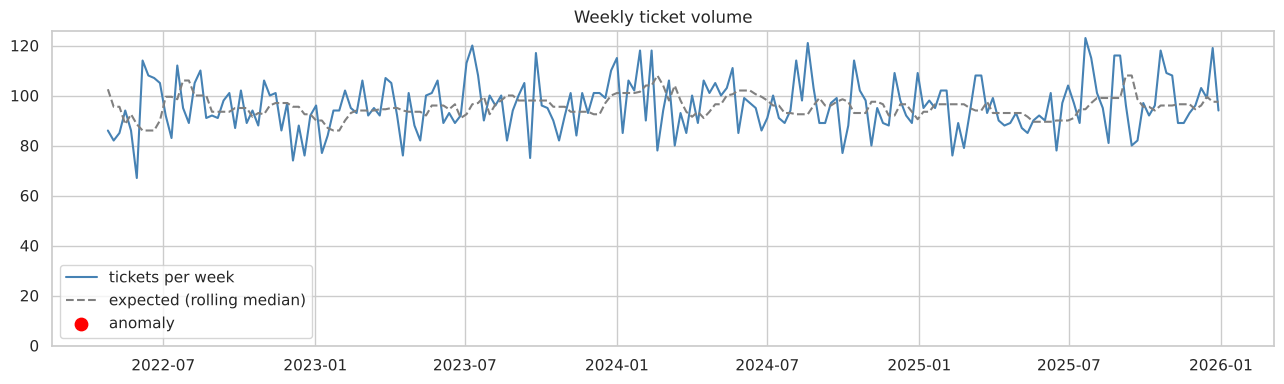

,count,expected,z,is_anomaly
created_at,,,,


In [2]:
def robust_z(series, window=8):
    past = series.shift(1)                                      # only look at earlier periods
    median = past.rolling(window).median()
    mad = (past - median).abs().rolling(window).median()        # median absolute deviation
    spread = np.maximum(1.4826 * mad, np.sqrt(median))          # never smaller than normal random (Poisson) noise
    return median, (series - median) / spread

def full_periods(df, freq):
    counts = df.groupby(pd.Grouper(key="created_at", freq=freq)).size()
    return counts.iloc[1:-1]                                    # drop partial first and last period

weekly = full_periods(tickets, "W-MON").to_frame("count")
weekly["expected"], weekly["z"] = robust_z(weekly["count"])
weekly["is_anomaly"] = weekly["z"].abs() >= Z_THRESHOLD
weekly = weekly.dropna()

plt.figure(figsize=(13, 4))
plt.plot(weekly.index, weekly["count"], label="tickets per week", color="steelblue")
plt.plot(weekly.index, weekly["expected"], label="expected (rolling median)", color="grey", ls="--")
flag = weekly[weekly["is_anomaly"]]
plt.scatter(flag.index, flag["count"], color="red", s=80, zorder=3, label="anomaly")
plt.ylim(0, None); plt.legend(); plt.title("Weekly ticket volume")
plt.tight_layout(); plt.savefig(FIG / "50_weekly_volume.png"); plt.show()

print(f"Weeks checked: {len(weekly)} | flagged: {weekly['is_anomaly'].sum()}")
flag

In [3]:
rows = []
for cat, g in tickets.groupby(TARGET):
    m = full_periods(g, "MS").to_frame("count")
    m["expected"], m["z"] = robust_z(m["count"], window=6)
    m["category"] = cat
    rows.append(m.dropna())
monthly = pd.concat(rows).reset_index().rename(columns={"created_at": "period"})
monthly["is_anomaly"] = monthly["z"].abs() >= Z_THRESHOLD
monthly["direction"] = np.where(monthly["z"] > 0, "spike", "drop")

print(f"Category-months checked: {len(monthly)} | flagged: {monthly['is_anomaly'].sum()}")
monthly[monthly["is_anomaly"]]

Category-months checked: 280 | flagged: 1


,period,count,expected,z,category,is_anomaly,direction
131,2025-03-01,70,44.0,3.188502,feature_request,True,spike


### Does the detector actually work? Plant some spikes and see

We copy the weekly series and add extra tickets to random weeks: first +20%, then +40%, and so on. For each size we plant 5 spikes
and count how many the detector catches. This tells us how big a jump has to be before we'd notice it.
We also work out how many flags we'd expect by pure chance at z ≥ 3, to judge whether the real flags mean anything.

In [4]:
rng = np.random.default_rng(SEED)
sensitivity = []
for jump in [0.2, 0.4, 0.6, 0.8, 1.0]:
    test_series = weekly["count"].astype(float).copy()
    planted = rng.choice(np.arange(10, len(test_series) - 1), size=5, replace=False)
    test_series.iloc[planted] *= 1 + jump
    _, z_test = robust_z(test_series)
    caught = int((z_test.iloc[planted].abs() >= Z_THRESHOLD).sum())
    sensitivity.append({"extra_tickets": f"+{jump:.0%}", "planted": 5, "caught": caught})
sensitivity = pd.DataFrame(sensitivity)

expected_by_chance = 2 * stats.norm.sf(Z_THRESHOLD) * (len(weekly) + len(monthly))
validation = pd.concat([
    sensitivity.assign(check=lambda d: "planted spikes " + d["extra_tickets"] + " caught",
                       result=lambda d: d["caught"].astype(str) + " / 5")[["check", "result"]],
    pd.DataFrame([["real weekly flags", str(int(weekly["is_anomaly"].sum()))],
                  ["real category-month flags", str(int(monthly["is_anomaly"].sum()))],
                  ["flags expected by pure chance", f"{expected_by_chance:.1f}"]], columns=["check", "result"]),
], ignore_index=True)
validation

,check,result
0,planted spikes +20% caught,1 / 5
1,planted spikes +40% caught,3 / 5
2,planted spikes +60% caught,5 / 5
3,planted spikes +80% caught,5 / 5
4,planted spikes +100% caught,5 / 5
5,real weekly flags,0
6,real category-month flags,1
7,flags expected by pure chance,1.3


**What this tells us**

- The real data has **no weekly spikes** and just **one** flagged category-month (feature_request in March 2025: 70 tickets vs about 44 expected).
  We'd expect about 1.3 flags across all these series purely by chance, so that single flag is consistent with random noise. We report it, but wouldn't sound an alarm on it alone.
- The planted-spike test shows the detector works: it catches every jump of +60% or more, and some jumps of +20–40%.
  With about 95 tickets a week, smaller jumps are hard to tell apart from normal week-to-week variation. More data per period would make the detector more sensitive.

So "no anomalies found" here is a real finding about this (synthetic, very steady) data, not a broken detector.

## 2. Hotspots: groups doing worse than average

For each group (each category, channel, region, product, priority...) we compare four rates with the overall rate:

- **negative sentiment**: customer was negative or very negative
- **reopened**: ticket had to be reopened
- **slow resolution**: resolved, but slower than 90% of tickets with the same priority
- **low model confidence**: our classifier wasn't sure (these need manual review)

We use a z-test for proportions. Because we test many groups, some will look unusual by chance, so we also apply a **Bonferroni correction**
(a stricter threshold that accounts for the number of tests).

In [5]:
resolved = tickets["status"] == "resolved"
p90 = tickets[resolved].groupby("priority")["resolution_time_hours"].quantile(0.9)
tickets["negative_sentiment"] = tickets["customer_sentiment"].isin(["negative", "very_negative"]).astype(float)
tickets["slow_resolution"] = np.where(resolved, tickets["resolution_time_hours"] > tickets["priority"].map(p90), np.nan)
tickets["low_confidence"] = tickets["needs_review"].astype(float)
tickets["reopened_flag"] = tickets["reopened"].astype(float)

metrics = ["negative_sentiment", "reopened_flag", "slow_resolution", "low_confidence"]
groups = [TARGET, "channel", "region", "product_area", "priority", "customer_segment", "platform", "sla_plan"]

rows = []
for metric in metrics:
    data = tickets.dropna(subset=[metric])
    overall = data[metric].mean()
    for col in groups:
        for value, g in data.groupby(col):
            n, rate = len(g), g[metric].mean()
            z = (rate - overall) / np.sqrt(overall * (1 - overall) / n)
            rows.append({"metric": metric, "group": col, "value": value, "tickets": n,
                         "rate": rate, "overall": overall, "z": z})
hotspots = pd.DataFrame(rows)
bonferroni_z = stats.norm.isf(0.05 / len(hotspots))
hotspots["significant"] = hotspots["z"] >= bonferroni_z
print(f"Tests run: {len(hotspots)} | Bonferroni threshold: z >= {bonferroni_z:.2f}")
print(f"Significant hotspots: {hotspots['significant'].sum()}")
hotspots[hotspots["significant"]].sort_values("z", ascending=False)[
    ["metric", "group", "value", "tickets", "rate", "overall", "z"]].style.format(
    {"rate": "{:.1%}", "overall": "{:.1%}", "z": "{:.1f}"}).hide(axis="index")

Tests run: 168 | Bonferroni threshold: z >= 3.43
Significant hotspots: 8


metric,group,value,tickets,rate,overall,z
low_confidence,issue_type,other,2492,100.0%,45.7%,54.4
low_confidence,issue_type,billing_problem,2476,100.0%,45.7%,54.2
low_confidence,issue_type,account_access,2522,67.1%,45.7%,21.6
low_confidence,issue_type,security_concern,2492,66.7%,45.7%,21.0
negative_sentiment,issue_type,performance,2503,60.8%,42.1%,19.0
negative_sentiment,issue_type,security_concern,2492,60.1%,42.1%,18.2
negative_sentiment,issue_type,billing_problem,2476,59.1%,42.1%,17.2
negative_sentiment,issue_type,account_access,2522,58.1%,42.1%,16.3


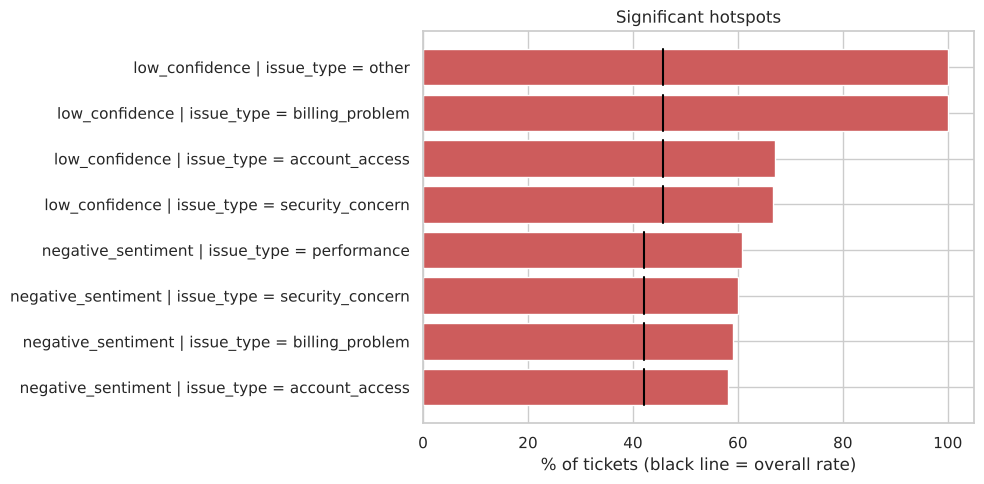

In [6]:
sig = hotspots[hotspots["significant"]].sort_values("z")
plt.figure(figsize=(10, 5))
plt.barh(sig["metric"] + " | " + sig["group"] + " = " + sig["value"].astype(str), sig["rate"] * 100, color="indianred",
         label="group rate")
for i, (_, r) in enumerate(sig.iterrows()):
    plt.plot([r["overall"] * 100] * 2, [i - 0.4, i + 0.4], color="black")
plt.xlabel("% of tickets (black line = overall rate)"); plt.title("Significant hotspots")
plt.tight_layout(); plt.savefig(FIG / "51_hotspots.png"); plt.show()

Eight hotspots survive the strict correction, and they tell two clear stories:

- **Customer frustration:** performance, security_concern, billing_problem and account_access tickets are about 60% negative, against 42% overall.
  These categories need the most attention for customer satisfaction.
- **Model uncertainty:** almost all `other`, `billing_problem`, `account_access` and `security_concern` tickets fall below the confidence threshold.
  That's the classifier struggling with classes it has few sentence types for (notebook 02). Operationally, these are the tickets that will land in manual review,
  so the triage team should expect most of its work from these four categories.

No channel, region, product, platform, segment or SLA plan stands out. Reopen and slow-resolution rates are even across all groups.

## 3. Unusual individual tickets: Isolation Forest

Isolation Forest builds many random trees that keep splitting the data. Unusual points get separated (isolated) after only a few splits,
so they get a high anomaly score. We use resolved tickets and five features describing how each one was handled:

- resolution time compared with the usual time for its priority
- priority, reopened or not, sentiment score, CSAT (blank CSAT filled with the middle value 3)

We flag the most unusual 1% and, for each, list the features that make it stand out.

In [7]:
res = tickets[resolved].copy()
res["time_vs_priority"] = res["resolution_time_hours"] / res.groupby("priority")["resolution_time_hours"].transform("median")
res["sentiment"] = res["customer_sentiment"].map({"very_negative": -2, "negative": -1, "neutral": 0,
                                                  "positive": 1, "very_positive": 2})
features = pd.DataFrame({
    "time_vs_priority": res["time_vs_priority"],
    "priority_rank": res["priority"].map({"low": 0, "medium": 1, "high": 2, "urgent": 3}),
    "reopened": res["reopened"],
    "sentiment": res["sentiment"],
    "csat": res["csat_score"].fillna(3),
})

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=SEED).fit(features)
res["anomaly_score"] = -iso.score_samples(features)          # higher = more unusual
res["is_anomaly"] = iso.predict(features) == -1

# explain each flagged ticket: which features are far from typical (in the "bad" direction)
z = (features - features.median()) / features.std()
direction = {"time_vs_priority": 1, "priority_rank": 1, "reopened": 1, "sentiment": -1, "csat": -1}
names = {"time_vs_priority": "slow for its priority", "priority_rank": "high priority", "reopened": "reopened",
         "sentiment": "negative customer", "csat": "low CSAT"}

def reasons(i):
    bad = [names[c] for c in features.columns if direction[c] * z.loc[i, c] > 1]
    return ", ".join(bad) if bad else "unusual combination"

flagged = res[res["is_anomaly"]].copy()
flagged["why"] = [reasons(i) for i in flagged.index]
print(f"Resolved tickets: {len(res)} | flagged as unusual: {len(flagged)}")
flagged["why"].value_counts().head(8)

Resolved tickets: 10119 | flagged as unusual: 102


why
reopened                                                        22
high priority, reopened                                         21
reopened, negative customer, low CSAT                           14
slow for its priority, high priority, reopened                   9
high priority, reopened, negative customer                       9
high priority, reopened, negative customer, low CSAT             7
high priority                                                    6
slow for its priority, reopened, negative customer, low CSAT     5
Name: count, dtype: int64

In [8]:
compare = pd.DataFrame({
    "flagged": flagged[["resolution_time_hours", "reopened", "csat_score"]].mean(),
    "all_resolved": res[["resolution_time_hours", "reopened", "csat_score"]].mean(),
})
compare.loc["negative_share"] = [flagged["negative_sentiment"].mean(), res["negative_sentiment"].mean()]
compare.round(2)

,flagged,all_resolved
resolution_time_hours,20.76,27.43
reopened,0.94,0.05
csat_score,3.24,3.21
negative_share,0.45,0.43


The flagged 1% are mostly **reopened tickets**, often combined with high priority, a negative customer or low CSAT.
Reopening is rare (5% of resolved tickets), so the forest isolates it quickly. That's sensible: a high-priority ticket that was "resolved" and then reopened
by an unhappy customer is exactly the kind of case a team lead should review.

These flagged tickets are actually resolved *faster* than average (21 vs 27 hours). That suggests a "closed too quickly, then reopened" pattern
worth checking in real data.

## 4. Save for the dashboard

In [9]:
weekly.reset_index().rename(columns={"created_at": "period"}).assign(category="ALL", direction="") \
      .pipe(lambda d: pd.concat([d, monthly])) \
      .to_csv(config.PROCESSED / "volume_anomalies.csv", index=False)
hotspots.to_csv(config.PROCESSED / "hotspots.csv", index=False)
flagged[["ticket_id", TARGET, "priority", "resolution_time_hours", "reopened", "csat_score",
         "customer_sentiment", "anomaly_score", "why"]].to_csv(config.PROCESSED / "ticket_anomalies.csv", index=False)
validation.to_csv(config.PROCESSED / "anomaly_validation.csv", index=False)
print("Saved volume_anomalies.csv, hotspots.csv, ticket_anomalies.csv, anomaly_validation.csv")

Saved volume_anomalies.csv, hotspots.csv, ticket_anomalies.csv, anomaly_validation.csv


## Summary

| Check | Result |
|---|---|
| Weekly volume spikes | None |
| Category-month spikes | 1 (feature_request, March 2025), in line with chance |
| Detector test | Catches all planted jumps of +60% or more |
| Hotspots (Bonferroni-corrected) | Problem categories ~60% negative; four categories mostly low-confidence for the model |
| Unusual tickets (Isolation Forest) | ~100 resolved tickets, mostly reopened, often high priority and unhappy customers |

Saved: `volume_anomalies.csv`, `hotspots.csv`, `ticket_anomalies.csv`, `anomaly_validation.csv` for the dashboard and the GenAI assistant.